# Assignment 1 — Working with Open Data

In this assignment you take a **real, public dataset**, ask questions of it, answer them, and document your work so that someone else could reproduce it.

**A few things to know before you start:**
- This course is about **data, not code.** The point of A1 is the analytical questions and what the numbers tell you about how people behave — *not* whether you remember Python syntax.
- You can do the analysis **in Python here, or in Google Sheets.** Every question below works either way. Pick whatever lets you think about the data instead of fighting the tool.
- You may use an **AI assistant** (ChatGPT, Claude, …) to help you write code — with rules. See *A note on using AI* at the bottom before you do.

**What you'll turn in** (committed to your `hcde-410` repo):
1. This notebook, with your answers filled in.
2. A short **README.md** describing your work.
3. A **LICENSE** file, and a note about the dataset's own license.

Your commit history is part of the record — commit as you go.

## Part 0 — Get the data

The data comes from [data.seattle.gov](https://data.seattle.gov/), the City of Seattle's open-data portal. We'll use the [Burke-Gilman Trail counter north of NE 70th St](https://data.seattle.gov/Transportation/Burke-Gilman-Trail-north-of-NE-70th-St-Bicycle-and/2z5v-ecg8), which records **bike and pedestrian traffic, by hour, by direction**.

We'll pull the data straight from the city's API rather than downloading a file by hand. That's a small reproducibility win: anyone who runs this notebook gets the same data the same way, and it's written down exactly where it came from.

In [3]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
# The dataset's API endpoint, and a query for one year of data (2019).
# You can paste the full URL into a browser to preview the raw data.
api_endpoint = "https://data.seattle.gov/resource/2z5v-ecg8.json?"
api_parameters = "$limit=50000&$where=date > '2019-01-01T00:00:00' AND date < '2020-01-01T00:00:00'"

response = requests.get(api_endpoint + api_parameters)
raw_data = response.json()
print("Downloaded", len(raw_data), "hourly records.")
# If this cell fails (e.g. the API is down), see the note below the next cell.

Downloaded 8759 hourly records.


Now load it into a **pandas DataFrame** — a table, like a spreadsheet you can compute with.

In [5]:
df = pd.DataFrame(raw_data)
df.head()

,date,bgt_north_of_ne_70th_total,ped_south,ped_north,bike_north,bike_south
0,2019-01-01T01:00:00.000,2,1,0,1,0
1,2019-01-01T02:00:00.000,1,0,0,0,1
2,2019-01-01T03:00:00.000,0,0,0,0,0
3,2019-01-01T04:00:00.000,1,0,0,1,0
4,2019-01-01T05:00:00.000,1,0,0,1,0


### Quick sanity checks

Whenever you work with data **you didn't create**, check that it means what you think before you analyze it. Two things need fixing here:
- the counts arrive as **text**, so we convert them to numbers;
- the `date` is a string, so we convert it to a real **datetime** and pull out the hour and weekday.

We'll also add tidy `bikes` and `peds` columns (north + south).

In [6]:
# convert the count columns from text to numbers
count_cols = ["bike_north", "bike_south", "ped_north", "ped_south", "bgt_north_of_ne_70th_total"]
df[count_cols] = df[count_cols].apply(pd.to_numeric, errors="coerce")

# convert the date string to a real datetime, and derive hour + weekday
df["date"] = pd.to_datetime(df["date"])
df["hour"] = df["date"].dt.hour
df["weekday"] = df["date"].dt.day_name()

# combined bike and pedestrian counts
df["bikes"] = df["bike_north"] + df["bike_south"]
df["peds"]  = df["ped_north"] + df["ped_south"]

df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8759 entries, 0 to 8758
Data columns (total 10 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   date                        8759 non-null   datetime64[ns]
 1   bgt_north_of_ne_70th_total  8759 non-null   int64         
 2   ped_south                   8759 non-null   int64         
 3   ped_north                   8759 non-null   int64         
 4   bike_north                  8759 non-null   int64         
 5   bike_south                  8759 non-null   int64         
 6   hour                        8759 non-null   int32         
 7   weekday                     8759 non-null   object        
 8   bikes                       8759 non-null   int64         
 9   peds                        8759 non-null   int64         
dtypes: datetime64[ns](1), int32(1), int64(7), object(1)
memory usage: 650.2+ KB


,date,bgt_north_of_ne_70th_total,ped_south,ped_north,bike_north,bike_south,hour,bikes,peds
count,8759,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000
mean,2019-07-02 12:00:00,58.423564,8.047380,8.363169,19.875671,22.137344,11.501313,42.013015,16.410549
min,2019-01-01 01:00:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2019-04-02 06:30:00,2.000000,0.000000,0.000000,0.000000,1.000000,6.000000,1.000000,0.000000
50%,2019-07-02 12:00:00,33.000000,5.000000,6.000000,9.000000,8.000000,12.000000,20.000000,11.000000
75%,2019-10-01 17:30:00,91.000000,13.000000,14.000000,31.000000,30.000000,17.500000,64.000000,27.000000
max,2019-12-31 23:00:00,1764.000000,1324.000000,782.000000,199.000000,961.000000,23.000000,1039.000000,1752.000000
std,NaN,73.656910,16.882468,13.164217,26.299728,34.080707,6.921886,56.534598,27.675776


**Look at what `describe()` tells you.** Are there hours with 0 traffic? Any missing values (a sensor can go offline)? Note anything odd — you'll want to mention data limitations later.
Yes, the minimum has an hour of 0.

**No-code option:** run the next cell to save the cleaned data as a CSV, then open it in Google Sheets and do your analysis there. If you go this route, title your sheet **"A1 — [your name]"**, share it so anyone with the link can view, and paste the link into your written answers.

In [7]:
df.to_csv("bg_hourly_2019.csv", index=False)
print("Saved bg_hourly_2019.csv — a row per hour of 2019.")

Saved bg_hourly_2019.csv — a row per hour of 2019.


## Part 1 — One worked example: when do cyclists ride?

Here is the whole technique, **once**, so you can see the pattern. After this, the questions are yours.

The move is always the same: **group → summarize → plot → interpret.** In pandas that's a couple of lines (no loops needed).

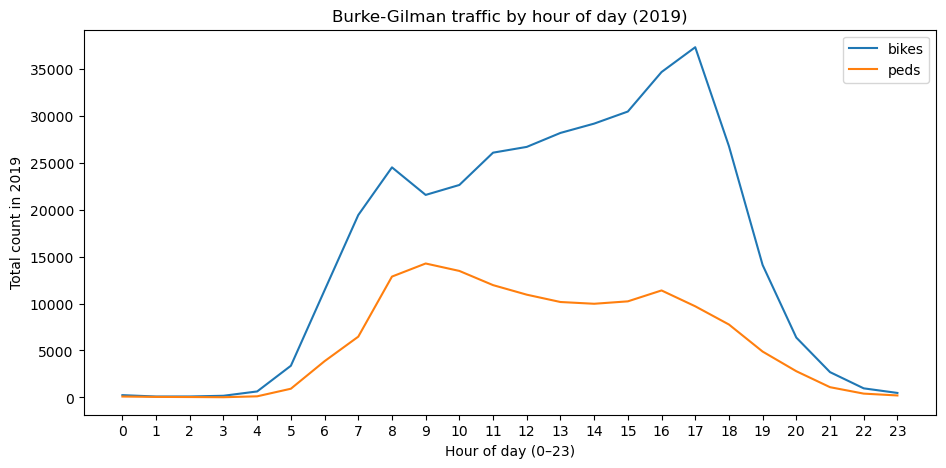

In [8]:
# group every row by its hour of day, and sum bikes and peds within each hour
by_hour = df.groupby("hour")[["bikes", "peds"]].sum()

by_hour.plot(figsize=(11, 5))
plt.title("Burke-Gilman traffic by hour of day (2019)")
plt.xlabel("Hour of day (0–23)")
plt.ylabel("Total count in 2019")
plt.xticks(range(0, 24))
plt.show()

**Now read the plot — this is the actual work.** What does the shape tell you? Do you see one peak or two? What might a double peak mean about *why* people are on the trail? That interpretation — turning a shape into a claim about human behavior — is what every question below is really asking for.

## Part 2 — Your analysis

Answer each question below. For every one:
1. **Show how you got there** — a pandas cell here, or (no-code) a link to your Google Sheet in the answer.
2. **Interpret it in 2–4 sentences** — what does this say about how people actually use the trail? The interpretation is the point, not the number.

There isn't a single right answer to most of these. Making a reasonable choice and *defending* it is the skill.

**Q1. When is the trail busiest, and when is it quietest?**
Decide what *busy* means to you first — a single hour? a stretch of the day? bikes and peds together, or separately? — and say why you chose that.

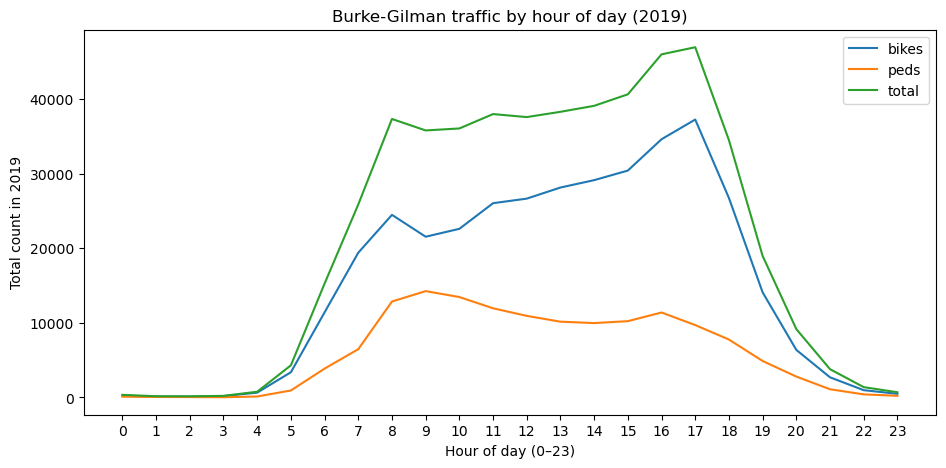

In [13]:
by_hour = df.groupby("hour")[["bikes", "peds"]].sum()
by_hour["total"] = by_hour["bikes"] + by_hour["peds"]

by_hour.plot(figsize=(11, 5))
plt.title("Burke-Gilman traffic by hour of day (2019)")
plt.xlabel("Hour of day (0–23)")
plt.ylabel("Total count in 2019")
plt.xticks(range(0, 24))
plt.show()


**Your Q1 answer:**

I would say a busy time of the day is a long stretch where the total count of pedestrians and cyclists is above a certain threshold of people. I define it this way because each cyclist and pedestrian is counted as a "body", so it would make the most sense to assume the busiest time is when the most "bodies" are on the trail, not separating them. Moreover, choosing a long stretch of the day is better representative of how consistently trafficked the trail is rather than a single hour where it only considers the absolute peak of traffic.

From the graph above, the absolute maximum for pedestrian and cyclists combined is 5:00PM. Referring to the y-axis, a good measurement for a threshold of people on the trail is when the total count is above 10,000. We can see the total count begins to jump in the morning at 5:30AM, and is slowly reaching a minimum around 8:00PM. In between those times (5:30AM to 8:00PM) the total count/traffic is actively increasing/decreasing or consistent at a maximum of people. That being said, we can move further with another threshold and consider that the total count of people remains close to or above 40,000 between 8:00AM and 5:00PM.

With these observations, I would conclude the trail is busiest between 8:00AM to 5:00PM, as that is where the threshold of people is close to or above 40,000. I would conclude the trail is quietest between 8:00PM to 5:30AM (the next day), as that is when the threshold of people is below 10,000.

**Q2. Do cyclists and pedestrians use the trail at different times of day?**
Compare their hourly patterns. If they differ, what might explain it?

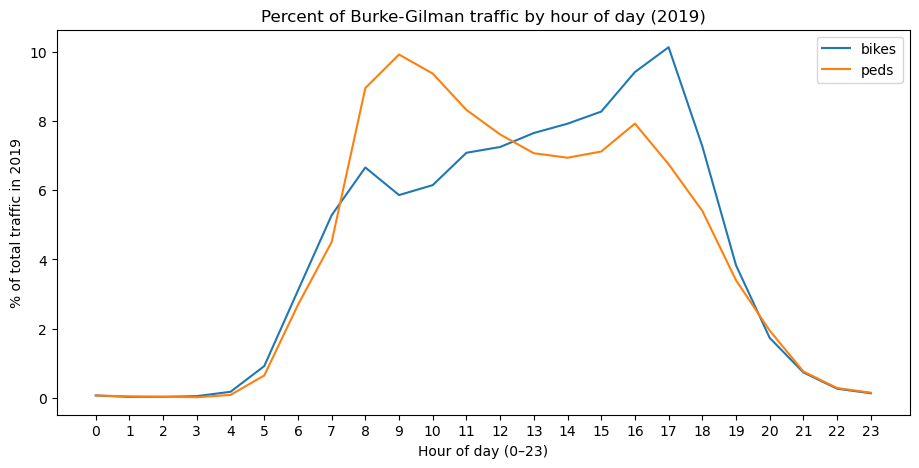

In [16]:
by_hour = df.groupby("hour")[["bikes", "peds"]].sum()
percent = by_hour / by_hour.sum()*100

percent.plot(figsize=(11, 5))
plt.title("Percent of Burke-Gilman traffic by hour of day (2019)")
plt.xlabel("Hour of day (0–23)")
plt.ylabel("% of total traffic in 2019")
plt.xticks(range(0, 24))
plt.show()



**Your Q2 answer:**

Despite sharing similar data, cyclists and pedestrians do not always use the trail at the same time of day! 

Looking at the graph, the percentage of total pedestrians and cyclists in 2019 is displayed for each hour of the day. The peak time that the most percentage of pedestrians are using the trail is at 9:00AM, where 10% of total pedestrians were counted for at that time. The peak time that the most percentage of cyclists are using the trail is at 5:00PM, where 10% of total cyclists were counted for at that time. We can conclude that although pedestrians and cyclists use the trail similarly by being active during the day time, they are less likely to encounter each other in the morning (when pedestrian counts are at a peak) and evening (when cyclist counts are at a peak).

For cyclists, they use the trail the most in the afternoon and early evening. I would determine that it is increasingly popular as the day progresses, possibly due to commuting and that biking can cover farther distances. And the later it gets in the day, the more and more people get off work, and/or use the trail after work. Moreover, the sharp decline at the end of the day for cyclists is likely due to the lack of sunlight and how quick darkness overcomes the city after sunset.

For pedestrians, they use the trail most in the early morning and afternoon. I would determine that it's most popular then because people prefer to walk leisurely in mornings, as they are aware of warmer temperatures in the day, and greater traffic of people (and as we can see, cyclists are more active in the afternoon and evening, which is **not** when pedestrians would want to walk).

**Q3. Commuting or recreation?**
Is there evidence people use the Burke-Gilman to *commute*, not just for fun? Compare **weekdays vs. weekends** (we made a `weekday` column for you), and maybe morning vs. evening. Define what a "commuting pattern" would look like in the data, then say whether you see it.

*Hint: `df.groupby("weekday")[["bikes","peds"]].sum()` gets you started. Weekends and weekdays will look different if commuting is real.*

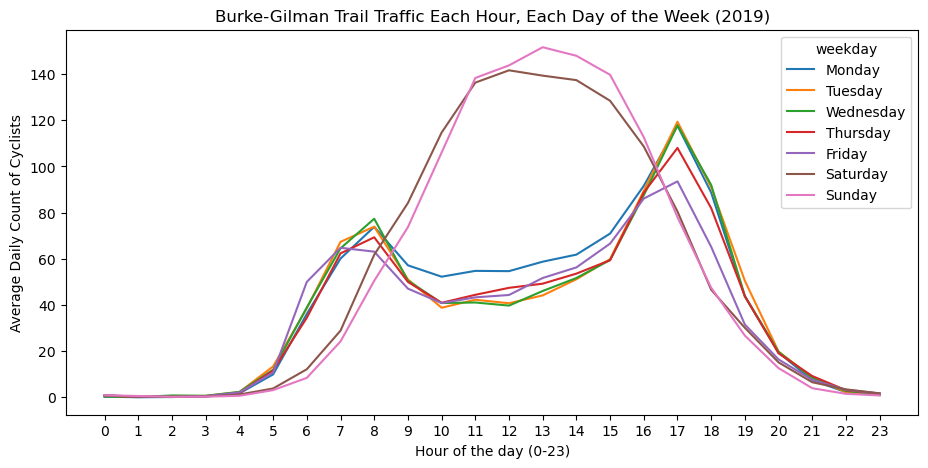

In [61]:
# Your code for Q3
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_week = df.groupby(["weekday", "hour"])[["bikes","peds"]].mean()

by_week["bikes"].unstack(0)[weekday_order].plot(figsize=(11,5))
plt.title("Burke-Gilman Trail Traffic Each Hour, Each Day of the Week (2019)")
plt.xlabel("Hour of the day (0-23)")
plt.ylabel("Average Daily Count of Cyclists")
plt.xticks(range(0, 24))
plt.show()

**Your Q3 answer:**

A "commuting pattern" in the data would mean the peak counts across the weekdays and weekends differs. This would make sense because commuting on a weekday falls under the morning and evening times where the peaks are, whereas recreation would mean people use the trail leisurely at a time where they are not commuting, on a weekend. 

As we can see from the graph, there is a significant jump in cyclists using the trail on the weekend in general. Furthermore, the peak count of cyclists is at 8:00AM and 5:00PM on weekdays, but for Saturday and Sunday that peak is found at 12:00PM-1:00PM. 

We can conclude from this data that the trail is definitely used for recreation on weekends where people have more availability (hence the high average count of cyclists), but also more freedom to choose when they want to use the trail, which is clearly in the afternoon rather than the morning or evening.

**Q4. Direction and flow.**
The counter records **north vs. south** separately. Are mornings mostly one direction and evenings the other? What would that tell you about who's using the trail and where they're heading?

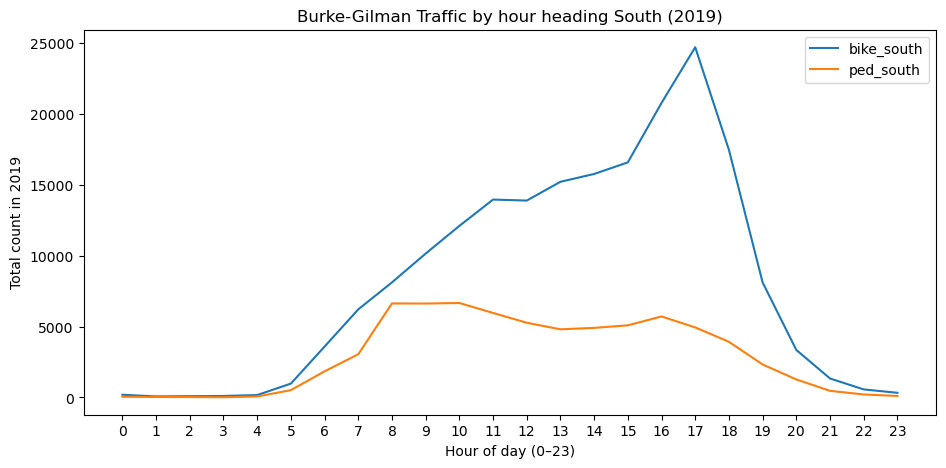

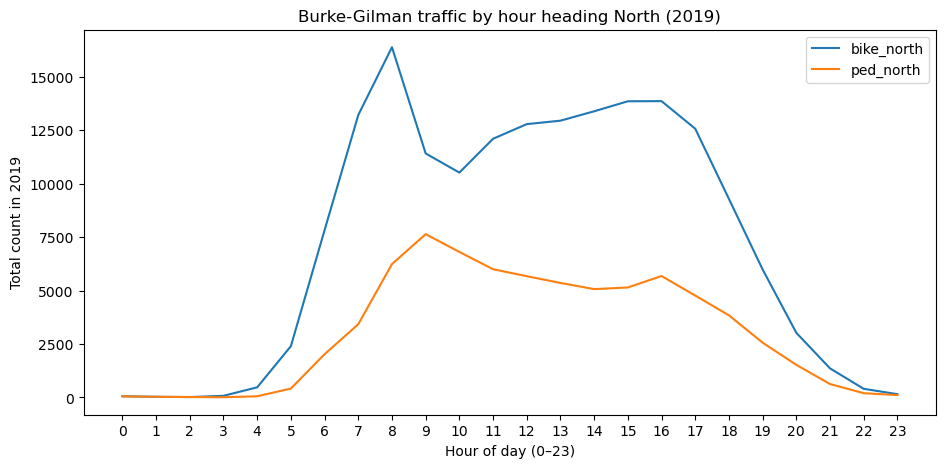

In [13]:
by_dir_south = df.groupby("hour")[["bike_south","ped_south"]].sum()
by_dir_north = df.groupby("hour")[["bike_north","ped_north"]].sum()

by_dir_south.plot(figsize=(11, 5))
plt.title("Burke-Gilman Traffic by hour heading South (2019)")
plt.xlabel("Hour of day (0–23)")
plt.ylabel("Total count in 2019")
plt.xticks(range(0, 24))
plt.show()

by_dir_north.plot(figsize=(11, 5))
plt.title("Burke-Gilman traffic by hour heading North (2019)")
plt.xlabel("Hour of day (0–23)")
plt.ylabel("Total count in 2019")
plt.xticks(range(0, 24))
plt.show()

**Your Q4 answer:**

The two graphs report how many cyclists and pedestrians are using the trail at each hour and the direction they are heading.

For the South graph, it is apparent that most cyclists use the trail to head South in the evening and early afternoon. From this, we can assume that most individuals who use the trail are commuting home to Seattle. Or, they live North, and are leisurely riding their bike after work along the rail.

For the North graph, it is a little trickier to decipher what is happening. I would say the graph is pretty similar to the total count of cyclists and pedestrians regardless of direction as they both follow an "M" shape. However, it is clear that cyclists heading North in the middle of the day are likely biking leisurely rather than commuting to work. 

Honestly, I would say from the graphs I've created that pedestrians are not really using this trail for commuting, as it is consistent amongst the data that regardless of direction, the number of people remains the same.

It's also important to note that some of the trail does not go directly North & South, it actually goes West or East, which raises questions about how the data determines what is North or South, and *where* those areas are that people are heading those directions.

## Part 3 — Make it reproducible

Good data work can be picked up and re-run by someone else. Two short deliverables:

**1. A `README.md`** in your `A1` folder. Use this template:

```
# A1 — Working with Open Data

**Dataset:** Burke-Gilman Trail counter north of NE 70th St
**Source:** https://data.seattle.gov/Transportation/.../2z5v-ecg8  (pulled YYYY-MM-DD)
**License / terms of use:** <find it on the dataset's page and note it here>

## Questions I asked
- ...

## How to re-run
Open `A1.ipynb` and run all cells (needs `requests`, `pandas`, `matplotlib`).
```

**2. A `LICENSE`** — keep the license file in this folder, and in your README **note the dataset's own license or terms of use** (open datasets almost always have one; find it on the dataset's page). Using open data responsibly means knowing what you're allowed to do with it — that's part of the assignment, not an afterthought.

### One more thing: read the data critically

In 3–4 sentences, name **one limitation or bias** in this dataset and how it could mislead someone who trusted it uncritically.

*(A sensor counts bodies, not intentions. It's one location on a long trail. Some hours may be missing when the counter was offline. A tandem bike counts once. What else?)* This is a warm-up for A2, where finding bias in data is the whole assignment.

**Your answer:**

One limitation in this dataset is that the data only records the direction of travel at a single point in time, and only focuses on people heading North and South, not West or East. This is not a full or accurate representation of where people are heading using the Burke-Gilman trail if they are only tracking two out of four directions, especially since the trail bends throughout. If someone were only heading North for a moment, and then diverted East, the counter is accurately considering that as "North", but does not tell us their whereabouts or direction outside of that point. This can be misrepresentative for someone who is trusting the data uncritically as they immediately assume a direction of the trail to be busier than it actually is. For example, if someone was reviewing this data and saw Southbound traffic to be busier in the evening, they would conclude the entire trail to be busy when the data only verifies a specific point on the trail and the direction at that specific point.



## Optional — going further

If you want to push further (not required for full credit):
- Which **day of the week** is busiest? Is it the same for bikes and pedestrians?
- Has the trail gotten **busier over time**? (the data goes back to 2014 — change the year in the query)
- Do fewer people ride when it's **cold or wet**? (join with a Seattle [weather dataset](https://data.seattle.gov/))
- Compare with another counter — the [Fremont Bridge](https://data.seattle.gov/Transportation/Fremont-Bridge-Bicycle-Counter/65db-xm6k) or the [MTS Trail](https://data.seattle.gov/Transportation/MTS-Trail-west-of-I-90-Bridge-Bicycle-and-Pedestri/u38e-ybnc).

## A note on using AI

You may use an LLM (ChatGPT, Claude, …) to help you write code or make a plot. Treat it as a **tool you supervise, not an author you trust**:
- paste the **prompt** you used into a Markdown cell,
- **run** the output and check it against what you expected,
- note **what you changed and why**.

Here, AI is your assistant. In **A3** it becomes your subject of study. Code that runs but that you can't explain won't earn credit — the point is that *you* can ask a question of data and defend the answer.



__I did not use AI for this assignment.__